# NSL-KDD Dataset Overview

Overview figures for the pitch deck: dataset composition, attack families, and
the concrete differences between **normal** and **attack** traffic.

> Dataset: **NSL-KDD** (labeled) — the cleaned successor to the KDD'99 network-intrusion benchmark.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from pathlib import Path

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
})

# palette (matches the QORC deck)
C_NORMAL = '#2AA9D6'   # photon cyan
C_ATTACK = '#E8890C'   # phase amber
CAT_COLORS = {'DoS':'#C0392B','Probe':'#E8890C','R2L':'#8E44AD','U2R':'#16A085','normal':'#2AA9D6'}

CSV = next(p for p in [
    '../../NSL_KDD_labeled.csv',
    'NSL_KDD_labeled.csv',
    r'D:\Python\AI\Code\ReservoirComputing\NSL_KDD_labeled.csv',
] if Path(p).exists())
df = pd.read_csv(CSV)
print('loaded:', CSV, '->', df.shape)

loaded: ../../NSL_KDD_labeled.csv -> (125973, 42)


In [2]:
# ---- label engineering ----
df['bin'] = np.where(df['label'] == 'normal', 'normal', 'attack')

cat_map = {
    'normal':'normal',
    'neptune':'DoS','smurf':'DoS','back':'DoS','teardrop':'DoS','pod':'DoS','land':'DoS',
    'apache2':'DoS','processtable':'DoS','mailbomb':'DoS','udpstorm':'DoS','worm':'DoS',
    'satan':'Probe','ipsweep':'Probe','portsweep':'Probe','nmap':'Probe','mscan':'Probe','saint':'Probe',
    'guess_passwd':'R2L','warezclient':'R2L','warezmaster':'R2L','ftp_write':'R2L','imap':'R2L',
    'multihop':'R2L','phf':'R2L','spy':'R2L','xlock':'R2L','xsnoop':'R2L','snmpguess':'R2L',
    'snmpgetattack':'R2L','httptunnel':'R2L','sendmail':'R2L','named':'R2L',
    'buffer_overflow':'U2R','loadmodule':'U2R','rootkit':'U2R','perl':'U2R',
    'sqlattack':'U2R','xterm':'U2R','ps':'U2R',
}
df['cat'] = df['label'].map(lambda x: cat_map.get(x, 'other'))

n_rows, n_feats = df.shape[0], df.shape[1] - 3  # minus label, bin, cat
print(f'{n_rows:,} records | {n_feats} features | '
      f"{(df.bin=='normal').sum():,} normal / {(df.bin=='attack').sum():,} attack")
print('attack families:', df.loc[df.cat!='normal','cat'].nunique(),
      '| distinct labels:', df.label.nunique())

125,973 records | 41 features | 67,343 normal / 58,630 attack


attack families: 4 | distinct labels: 23


## 1. Dataset at a glance

C:\Users\binh1\AppData\Local\Temp\ipykernel_30920\3229793463.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


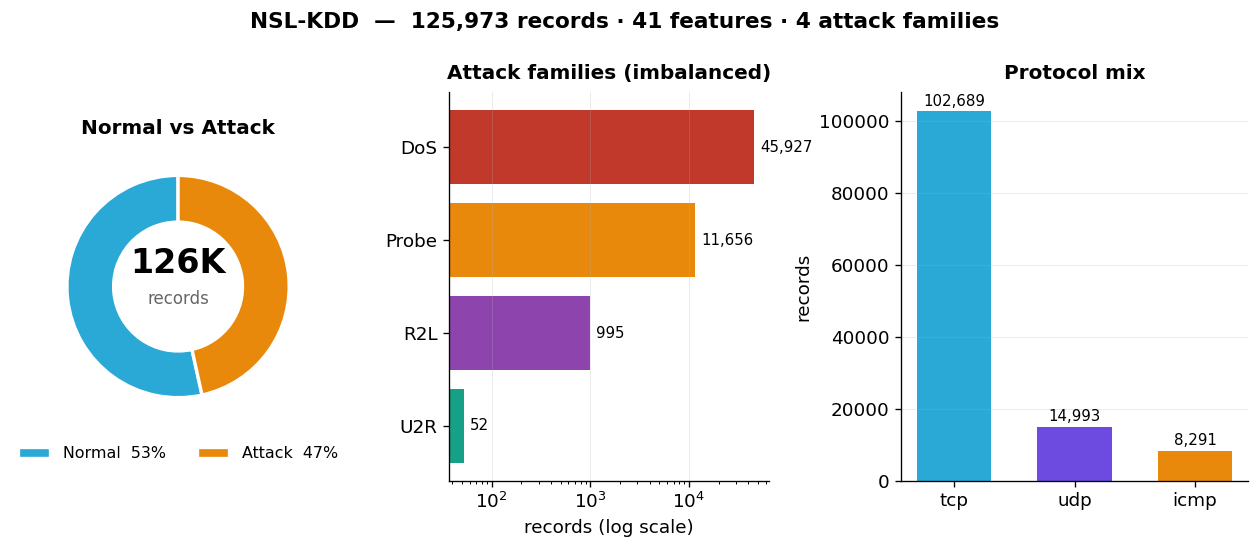

In [3]:
fig = plt.figure(figsize=(13, 4.2))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.15, 1.25], wspace=0.42)

# (a) normal vs attack donut
ax0 = fig.add_subplot(gs[0])
counts = [(df.bin=='normal').sum(), (df.bin=='attack').sum()]
wedges,_ = ax0.pie(counts, colors=[C_NORMAL, C_ATTACK], startangle=90,
                   wedgeprops=dict(width=0.42, edgecolor='white', linewidth=2))
ax0.text(0, 0.12, f'{n_rows/1000:.0f}K', ha='center', fontsize=20, fontweight='bold')
ax0.text(0, -0.16, 'records', ha='center', fontsize=10, color='#666')
ax0.set_title('Normal vs Attack', fontsize=12, fontweight='bold', pad=8)
ax0.legend([f'Normal  {counts[0]/n_rows*100:.0f}%',
            f'Attack  {counts[1]/n_rows*100:.0f}%'],
           loc='lower center', bbox_to_anchor=(0.5,-0.18), frameon=False, fontsize=9.5, ncol=2)

# (b) attack families (log scale to show minority classes)
ax1 = fig.add_subplot(gs[1])
fam = df[df.cat!='normal']['cat'].value_counts()
order = ['DoS','Probe','R2L','U2R']
fam = fam.reindex(order)
bars = ax1.barh(range(len(fam)), fam.values, color=[CAT_COLORS[c] for c in fam.index])
ax1.set_yticks(range(len(fam))); ax1.set_yticklabels(fam.index)
ax1.invert_yaxis(); ax1.set_xscale('log'); ax1.set_xlabel('records (log scale)')
ax1.set_title('Attack families (imbalanced)', fontsize=12, fontweight='bold', pad=8)
for i,(v) in enumerate(fam.values):
    ax1.text(v*1.15, i, f'{v:,}', va='center', fontsize=9)
ax1.grid(axis='y', alpha=0)

# (c) protocol mix
ax2 = fig.add_subplot(gs[2])
proto = df['protocol_type'].value_counts()
ax2.bar(proto.index, proto.values, color=['#2AA9D6','#6D4AE0','#E8890C'], width=0.62)
ax2.set_title('Protocol mix', fontsize=12, fontweight='bold', pad=8)
ax2.set_ylabel('records')
for i,v in enumerate(proto.values):
    ax2.text(i, v+1500, f'{v:,}', ha='center', fontsize=9)
ax2.grid(axis='x', alpha=0)

fig.suptitle('NSL-KDD  —  125,973 records · 41 features · 4 attack families',
             fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig('fig_dataset_glance.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Normal vs Attack — how they differ

Attack traffic is not random noise: it leaves **statistical fingerprints**. A few
features separate the two classes almost on their own.

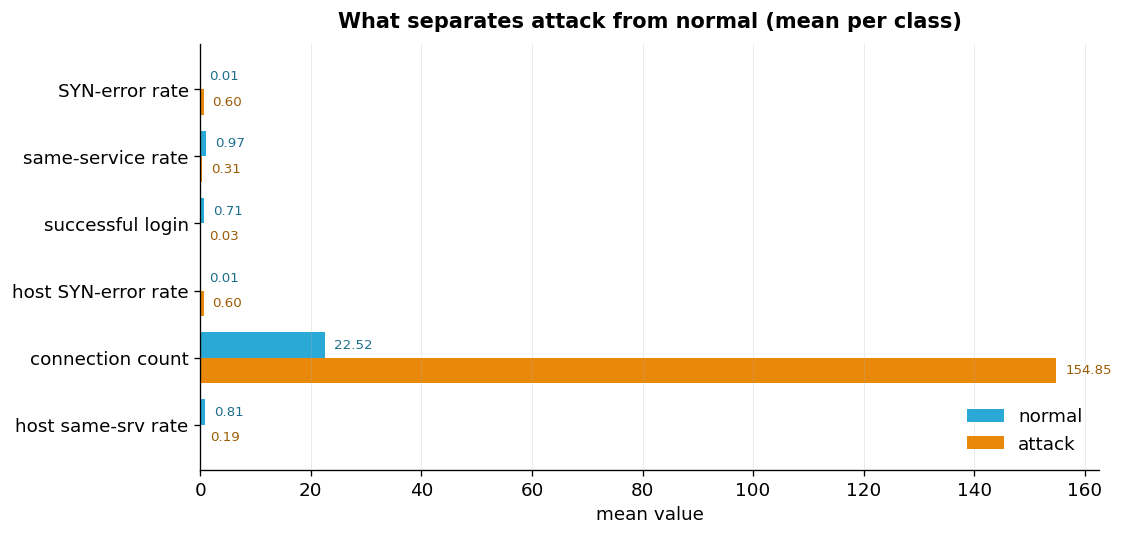

In [4]:
# mean value per class for the most discriminative behavioural features
feat_labels = {
    'serror_rate':      'SYN-error rate',
    'same_srv_rate':    'same-service rate',
    'logged_in':        'successful login',
    'dst_host_serror_rate':'host SYN-error rate',
    'count':            'connection count',
    'dst_host_same_srv_rate':'host same-srv rate',
}
feats = [f for f in feat_labels if f in df.columns]
means = df.groupby('bin')[feats].mean()

fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(feats)); h = 0.38
# normalise rate-like (0-1) vs count features for a shared view: use raw but split axis via annotation
norm_vals = means.loc['normal', feats].values
att_vals  = means.loc['attack', feats].values
ax.barh(y-h/2, norm_vals, h, color=C_NORMAL, label='normal')
ax.barh(y+h/2, att_vals,  h, color=C_ATTACK, label='attack')
ax.set_yticks(y); ax.set_yticklabels([feat_labels[f] for f in feats]); ax.invert_yaxis()
ax.set_xlabel('mean value')
ax.set_title('What separates attack from normal (mean per class)',
             fontsize=12.5, fontweight='bold', pad=10)
ax.legend(frameon=False, loc='lower right')
for yi,(n,a) in enumerate(zip(norm_vals, att_vals)):
    ax.text(n+ax.get_xlim()[1]*0.01, yi-h/2, f'{n:.2f}', va='center', fontsize=8, color='#1c6f8c')
    ax.text(a+ax.get_xlim()[1]*0.01, yi+h/2, f'{a:.2f}', va='center', fontsize=8, color='#9c5c06')
ax.grid(axis='y', alpha=0)
plt.tight_layout()
plt.savefig('fig_normal_vs_attack_bars.png', dpi=150, bbox_inches='tight')
plt.show()

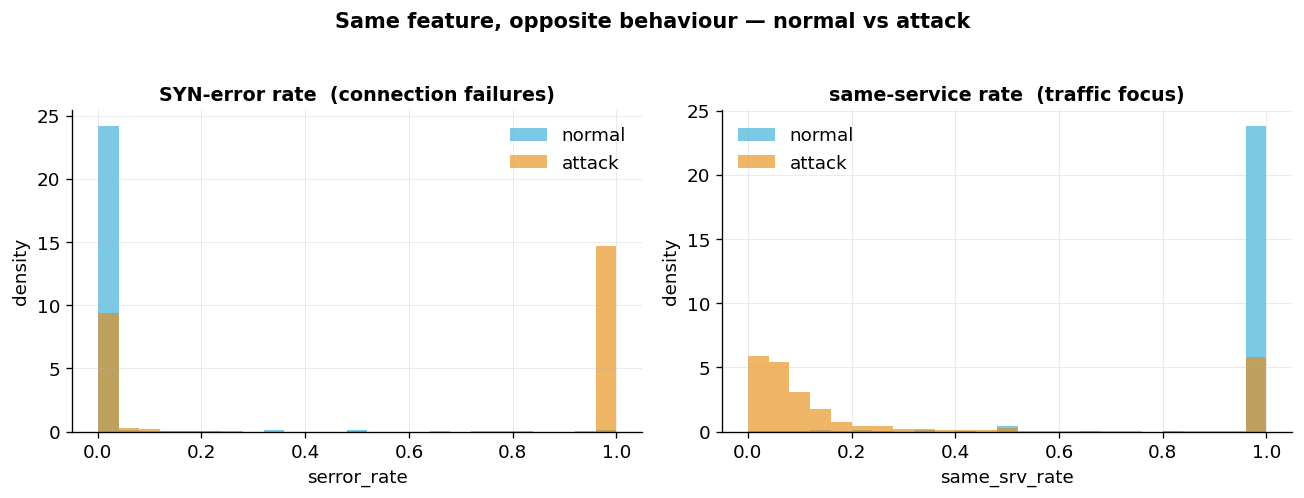

In [5]:
# distribution view: two features where the classes clearly split
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, feat, title in [
    (axes[0], 'serror_rate',   'SYN-error rate  (connection failures)'),
    (axes[1], 'same_srv_rate', 'same-service rate  (traffic focus)'),
]:
    for cls, col in [('normal', C_NORMAL), ('attack', C_ATTACK)]:
        vals = df.loc[df.bin==cls, feat]
        ax.hist(vals, bins=25, range=(0,1), alpha=0.62, density=True,
                color=col, label=cls)
    ax.set_title(title, fontsize=11.5, fontweight='bold')
    ax.set_xlabel(feat); ax.set_ylabel('density'); ax.legend(frameon=False)

fig.suptitle('Same feature, opposite behaviour — normal vs attack',
             fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('fig_normal_vs_attack_dist.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. The zero-day framing

Some attacks carry a near-unique **fingerprint** (one protocol/service/flag combo
identifies them) — trivially detectable. The honest challenge is the attacks with
**low fingerprint concentration**, which is where a richer feature map must earn its keep.

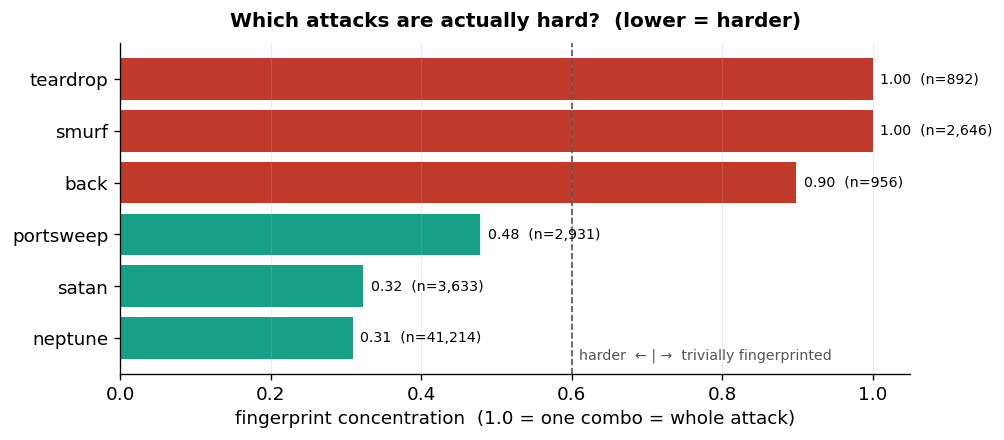

In [6]:
cat_cols = ['protocol_type','service','flag']
ATTACKS = ['smurf','teardrop','back','portsweep','satan','neptune']
rows = []
for a in ATTACKS:
    sub = df[df.label==a]
    conc = sub.groupby(cat_cols).size().max()/len(sub)
    rows.append((a, len(sub), conc))
fp = pd.DataFrame(rows, columns=['attack','n','fingerprint_conc']).set_index('attack')
fp = fp.sort_values('fingerprint_conc', ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
colors = ['#16A085' if c < 0.6 else '#C0392B' for c in fp.fingerprint_conc]
ax.barh(range(len(fp)), fp.fingerprint_conc, color=colors)
ax.set_yticks(range(len(fp))); ax.set_yticklabels(fp.index)
ax.axvline(0.6, color='#555', ls='--', lw=1)
ax.text(0.61, -0.4, 'harder  ← | →  trivially fingerprinted', fontsize=8.5, color='#555')
ax.set_xlim(0,1.05); ax.set_xlabel('fingerprint concentration  (1.0 = one combo = whole attack)')
ax.set_title('Which attacks are actually hard?  (lower = harder)',
             fontsize=12, fontweight='bold', pad=10)
for i,(c,n) in enumerate(zip(fp.fingerprint_conc, fp.n)):
    ax.text(c+0.01, i, f'{c:.2f}  (n={n:,})', va='center', fontsize=8.5)
ax.grid(axis='y', alpha=0)
plt.tight_layout()
plt.savefig('fig_fingerprint_conc.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# quick text summary block for the slide
print('DATASET SUMMARY  —  NSL-KDD')
print('='*46)
print(f'  records          : {n_rows:,}')
print(f'  features         : 41  (38 numeric + 3 categorical)')
print(f'  classes          : normal + {df.label.nunique()-1} attack types')
print(f'  attack families  : DoS, Probe, R2L, U2R')
print(f'  balance          : {(df.bin=="normal").mean()*100:.0f}% normal / {(df.bin=="attack").mean()*100:.0f}% attack')
print(f'  categorical dims : protocol_type(3), service(70), flag(11)')
print(f'  after one-hot    : 122 model features')

DATASET SUMMARY  —  NSL-KDD
  records          : 125,973
  features         : 41  (38 numeric + 3 categorical)
  classes          : normal + 22 attack types
  attack families  : DoS, Probe, R2L, U2R
  balance          : 53% normal / 47% attack
  categorical dims : protocol_type(3), service(70), flag(11)
  after one-hot    : 122 model features
